In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [61]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/loan_approval_20000.csv")

In [62]:
df.head()

,Applicant_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,APP000001,Male,No,1,Graduate,No,86082,0,389.0,180,1.0,Urban,Approved
1,APP000002,Male,Yes,0,Graduate,No,24335,7846,138.0,360,1.0,Urban,Approved
2,APP000003,Female,Yes,1,Graduate,No,17321,10511,20.0,420,1.0,Urban,Approved
3,APP000004,Female,Yes,0,Not Graduate,No,78035,1015,269.0,240,1.0,Semiurban,Approved
4,APP000005,Female,Yes,0,Not Graduate,No,25057,6006,87.0,360,1.0,Urban,Rejected


In [63]:
df.tail()

,Applicant_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
19995,APP019996,Male,No,0,Graduate,Yes,65704,0,84.0,240,1.0,Semiurban,Approved
19996,APP019997,Male,Yes,3+,Graduate,No,64367,19164,274.0,180,0.0,Semiurban,Approved
19997,APP019998,Male,No,2,Graduate,Yes,28911,0,69.0,420,1.0,Rural,Approved
19998,APP019999,Male,Yes,0,Graduate,No,45444,26674,236.0,300,1.0,Semiurban,Approved
19999,APP020000,Male,Yes,0,Graduate,No,21182,21835,95.0,420,1.0,Semiurban,Approved


In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Applicant_ID       20000 non-null  object 
 1   Gender             19791 non-null  object 
 2   Married            20000 non-null  object 
 3   Dependents         19708 non-null  object 
 4   Education          20000 non-null  object 
 5   Self_Employed      19787 non-null  object 
 6   ApplicantIncome    20000 non-null  int64  
 7   CoapplicantIncome  20000 non-null  int64  
 8   LoanAmount         19811 non-null  float64
 9   Loan_Amount_Term   20000 non-null  int64  
 10  Credit_History     19601 non-null  float64
 11  Property_Area      20000 non-null  object 
 12  Loan_Status        20000 non-null  object 
dtypes: float64(2), int64(3), object(8)
memory usage: 2.0+ MB


In [65]:
df.shape

(20000, 13)

In [66]:
df.columns

Index(['Applicant_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='object')

In [67]:
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,20000.000000,20000.000000,19811.000000,20000.000000,19601.000000
mean,47630.306350,6806.301900,203.205643,319.464000,0.822254
std,24397.358344,11574.656248,119.630190,73.920403,0.382309
min,12000.000000,0.000000,20.000000,120.000000,0.000000
25%,30506.000000,0.000000,118.000000,300.000000,1.000000
50%,42462.000000,1633.000000,180.000000,360.000000,1.000000
75%,58451.000000,9501.250000,263.000000,360.000000,1.000000
max,250000.000000,150000.000000,700.000000,420.000000,1.000000


In [68]:
df.size

260000

In [69]:
df.isnull().sum()

Applicant_ID           0
Gender               209
Married                0
Dependents           292
Education              0
Self_Employed        213
ApplicantIncome        0
CoapplicantIncome      0
LoanAmount           189
Loan_Amount_Term       0
Credit_History       399
Property_Area          0
Loan_Status            0
dtype: int64

In [70]:
df.duplicated().sum()

np.int64(0)

In [71]:
df["Gender"]=df["Gender"].fillna(df["Gender"].mode()[0])
df["Dependents"]=df["Dependents"].fillna(df["Dependents"].mode()[0])
df["Self_Employed"]=df["Self_Employed"].fillna(df["Self_Employed"].mode()[0])
df["LoanAmount"]=df["LoanAmount"].fillna(df["LoanAmount"].mode()[0])
df["Credit_History"]=df["Credit_History"].fillna(df["Credit_History"].mean())

In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Applicant_ID       20000 non-null  object 
 1   Gender             20000 non-null  object 
 2   Married            20000 non-null  object 
 3   Dependents         20000 non-null  object 
 4   Education          20000 non-null  object 
 5   Self_Employed      20000 non-null  object 
 6   ApplicantIncome    20000 non-null  int64  
 7   CoapplicantIncome  20000 non-null  int64  
 8   LoanAmount         20000 non-null  float64
 9   Loan_Amount_Term   20000 non-null  int64  
 10  Credit_History     20000 non-null  float64
 11  Property_Area      20000 non-null  object 
 12  Loan_Status        20000 non-null  object 
dtypes: float64(2), int64(3), object(8)
memory usage: 2.0+ MB


In [73]:
df.isnull().sum()

Applicant_ID         0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [74]:
X=df.drop(columns="Loan_Status",axis=1)
y=df["Loan_Status"].map({
    "Rejected":0,
    "Approved":1
})

In [75]:
num_cal=X.select_dtypes(include=["int64","float64"]).columns.tolist()
cat_cal=X.select_dtypes(include=["object"]).columns.tolist()

In [76]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(16000, 12)
(4000, 12)
(16000,)
(4000,)


# Preprocessing

In [77]:
num_pipeline=Pipeline(steps=[
    ("impute",SimpleImputer(strategy="median")),
    ("scler",StandardScaler())
])

cat_pipeline=Pipeline(steps=[
    ("impute",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

In [78]:
preprocessing=ColumnTransformer(transformers=[
    ("num",num_pipeline,num_cal),
    ("cat",cat_pipeline,cat_cal)
])

In [79]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced")

model=Pipeline(steps=[
    ("preprocessing",preprocessing),
    ("model",dt_model)
    
])

# Hyperparameter tuning using GridSearchCV

In [80]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]}

In [81]:
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=1)
grid_search.fit(X_train,y_train)

Fitting 3 folds for each of 90 candidates, totalling 270 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__criterion': ['gini', 'entropy'], 'model__max_depth': [3, 5, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluatio

In [82]:
y_pred=grid_search.predict(X_test)

In [83]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay)

In [84]:
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)

Accuracy: 0.794


# Best parameters

In [85]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)

Best Parameters: {'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 4, 'model__min_samples_split': 2}
Best CV F1 Score: 0.8845159777593937


# Model evaluation

In [86]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_pred))

Accuracy: 0.794
Precision: 0.9011590470057952
Recall: 0.8440892641737032
F1 Score: 0.8716910619744628
ROC-AUC: 0.6976294274084891


# Classification report

In [87]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.42      0.55      0.48       684
           1       0.90      0.84      0.87      3316

    accuracy                           0.79      4000
   macro avg       0.66      0.70      0.67      4000
weighted avg       0.82      0.79      0.80      4000



# Confusion matrix

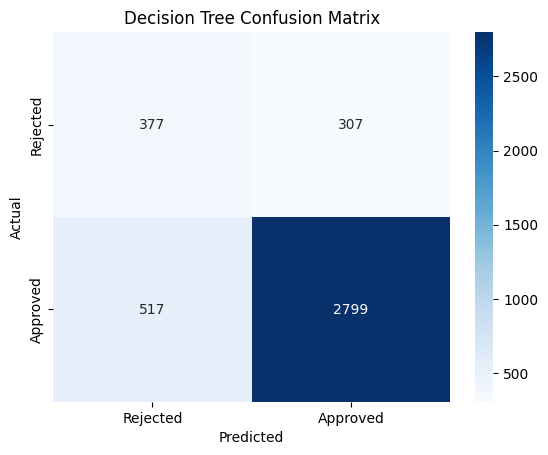

In [88]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.show()

# ROC Curve

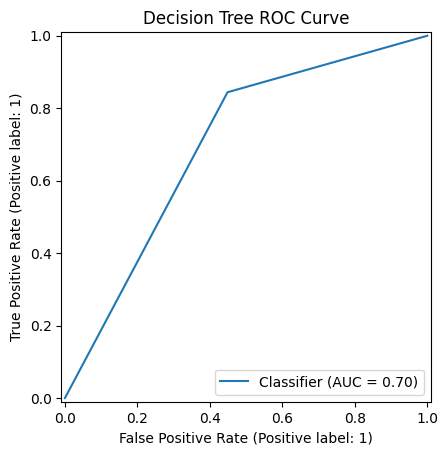

In [89]:
RocCurveDisplay.from_predictions(y_test, y_pred)
plt.title("Decision Tree ROC Curve")
plt.show()